# P3 — When does blur help a traffic-sign classifier?

**Vis4AI · Phase I: Black-box behavior**

We study a trained traffic-sign classifier by changing its input images and comparing its predictions. We do not inspect or retrain the model.

- **Model:** [ViT traffic-sign classifier](https://huggingface.co/kelvinandreas/vit-traffic-sign-GTSRB)
- **Dataset:** [GTSRB test split](https://huggingface.co/datasets/tanganke/gtsrb) — all 12,630 images, 43 classes
- **Method:** Evaluate the original images, find a frequent error, then test several Gaussian blur levels on the same images

Run the notebook from top to bottom. Required packages: `torch`, `transformers`, `datasets`, `pillow`, `numpy`, `pandas`, `matplotlib`, and `ipython`. Install any missing packages in your chosen Python environment. The full inference takes substantial time; cached predictions allow interrupted runs to resume. Results are saved in `p3_full_results/`.

AI assistance was used to develop and refactor this notebook. All claims here concern observed input-output behavior, not the model's internal reasoning.

## 1. Exploration — load the test data and model

We use the whole test split and check that the model and dataset have 43 classes. We keep the original model, preprocessing and evaluation settings.

In [1]:
from pathlib import Path
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
import torch
from datasets import load_dataset
from transformers import AutoImageProcessor, AutoModelForImageClassification
from IPython.display import display

MODEL = "kelvinandreas/vit-traffic-sign-GTSRB"
DATASET = "tanganke/gtsrb"
SPLIT = "test"
BLUR_LEVELS = [0, 0.5, 1, 1.5, 2, 2.5, 3, 5]
BATCH_SIZE = 16
CHUNK_SIZE = 128
OUT = Path("p3_full_results")
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Fixed experiment labels are used in the cached probability columns.
FOCUS_CLASS = 26
CONFUSED_CLASS = 18

COLORS = {
    "overall": "#34495e",
    "correct": "#2a9d8f",
    "confused": "#e76f51",
    "other": "#a6a6a6",
}

print("Device:", DEVICE)

Device: cuda


In [2]:
test = load_dataset(DATASET, split=SPLIT)
labels = np.asarray(test["label"], dtype=np.int64)
class_names = test.features["label"].names
assert len(test) == len(labels) == 12630
assert len(class_names) == 43

processor = AutoImageProcessor.from_pretrained(MODEL, use_fast=False)
model = AutoModelForImageClassification.from_pretrained(MODEL).to(DEVICE).eval()
assert model.config.num_labels == 43

def model_name(label):
    return str(model.config.id2label.get(int(label), class_names[int(label)]))

# Check the class names before interpreting the later confusion results.
assert "traffic" in model_name(FOCUS_CLASS).lower()
assert "caution" in model_name(CONFUSED_CLASS).lower()

print(f"{len(test):,} test images, {len(class_names)} classes")

c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\transformers\models\vit\feature_extraction_vit.py:30: FutureWarning: The class ViTFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use ViTImageProcessor instead.
  warnings.warn(


12,630 test images, 43 classes


## 2. Discovery — which signs are misclassified?

First, evaluate the unmodified images. Then count each true-class → predicted-class error. We use both the number of errors and the proportion within the true class, since classes contain different numbers of images.

In [3]:
def predict_probabilities(images):
    """Predict class probabilities for a list of images."""
    all_probs = []
    for start in range(0, len(images), BATCH_SIZE):
        batch_images = images[start:start + BATCH_SIZE]
        inputs = processor(images=batch_images, return_tensors="pt")
        inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
        with torch.inference_mode():
            probs = model(**inputs).logits.softmax(dim=-1).cpu().numpy()
        all_probs.append(probs)
    return np.concatenate(all_probs, axis=0)

CACHE = OUT / "cache"
CACHE.mkdir(parents=True, exist_ok=True)
settings = {
    "model": MODEL,
    "model_commit": str(getattr(model.config, "_commit_hash", None)),
    "dataset": DATASET,
    "split": SPLIT,
    "dataset_fingerprint": str(getattr(test, "_fingerprint", None)),
    "number_of_images": len(test),
    "blur_levels": BLUR_LEVELS,
    "chunk_size": CHUNK_SIZE,
}
manifest_path = CACHE / "settings.json"
if manifest_path.exists():
    if json.loads(manifest_path.read_text(encoding="utf-8")) != settings:
        raise RuntimeError("Previous checkpoints use different settings. Move/rename p3_full_results/cache before rerunning.")
else:
    manifest_path.write_text(json.dumps(settings, indent=2), encoding="utf-8")

def run_one_blur(radius):
    """Evaluate one blur level and reuse saved chunks if available."""
    folder = CACHE / f"blur_{radius:g}"
    folder.mkdir(exist_ok=True)
    tables = []
    total_chunks = (len(test) + CHUNK_SIZE - 1) // CHUNK_SIZE

    for chunk_number, start in enumerate(range(0, len(test), CHUNK_SIZE), start=1):
        end = min(start + CHUNK_SIZE, len(test))
        file = folder / f"chunk_{start:05d}.npz"
        expected_ids = np.arange(start, end)

        if file.exists():
            with np.load(file) as stored:
                saved = {key: stored[key] for key in stored.files}
            assert np.array_equal(saved["image_id"], expected_ids), f"Unexpected cached IDs in {file}"
        else:
            part = test[start:end]
            pictures = [im.convert("RGB") for im in part["image"]]
            if radius > 0:
                pictures = [im.filter(ImageFilter.GaussianBlur(radius)) for im in pictures]
            probs = predict_probabilities(pictures)
            top_two = np.partition(probs, -2, axis=1)[:, -2:]
            saved = {
                "image_id": expected_ids,
                "true_label": labels[start:end],
                "prediction": probs.argmax(axis=1),
                "confidence": probs.max(axis=1),
                "top_margin": top_two.max(axis=1) - top_two.min(axis=1),
                "p_true": probs[np.arange(len(probs)), labels[start:end]],
                "p_26": probs[:, FOCUS_CLASS],
                "p_18": probs[:, CONFUSED_CLASS],
            }
            temp_file = str(file) + ".tmp"
            with open(temp_file, "wb") as handle:
                np.savez_compressed(handle, **saved)
            os.replace(temp_file, file)  # Keep interrupted runs from leaving partial files

        table = pd.DataFrame(saved)
        table["blur"] = float(radius)
        tables.append(table)
        if chunk_number == total_chunks:
            print(f"Blur {radius:g}: {total_chunks} chunks ready")
    return pd.concat(tables, ignore_index=True)


# Start with the original images so the choice of focus class comes from the data.
baseline = run_one_blur(0)
baseline["correct"] = baseline["true_label"] == baseline["prediction"]
assert len(baseline) == len(test)
assert baseline.image_id.is_unique
print(f"No blur: {baseline.correct.mean():.2%} accuracy; {(~baseline.correct).sum()} errors")

Blur 0: 99 chunks ready
No blur: 95.38% accuracy; 584 errors


,pair,errors,class_total,rate_pct
77,26 Traffic signals → 18 General caution,54,180,30.00
47,12 Priority road → 40 Roundabout mandatory,51,690,7.39
116,38 Keep right → 17 No entry,44,690,6.38
98,35 Ahead only → 3 Speed limit (60km/h),29,390,7.44
6,3 Speed limit (60km/h) → 5 Speed limit (80km/h),25,450,5.56
102,35 Ahead only → 14 Stop,24,390,6.15
96,33 Turn right ahead → 34 Turn left ahead,16,210,7.62
14,6 End of speed limit (80km/h) → 32 End speed +...,12,150,8.00
25,8 Speed limit (120km/h) → 40 Roundabout mandatory,11,450,2.44
11,5 Speed limit (80km/h) → 2 Speed limit (50km/h),11,630,1.75


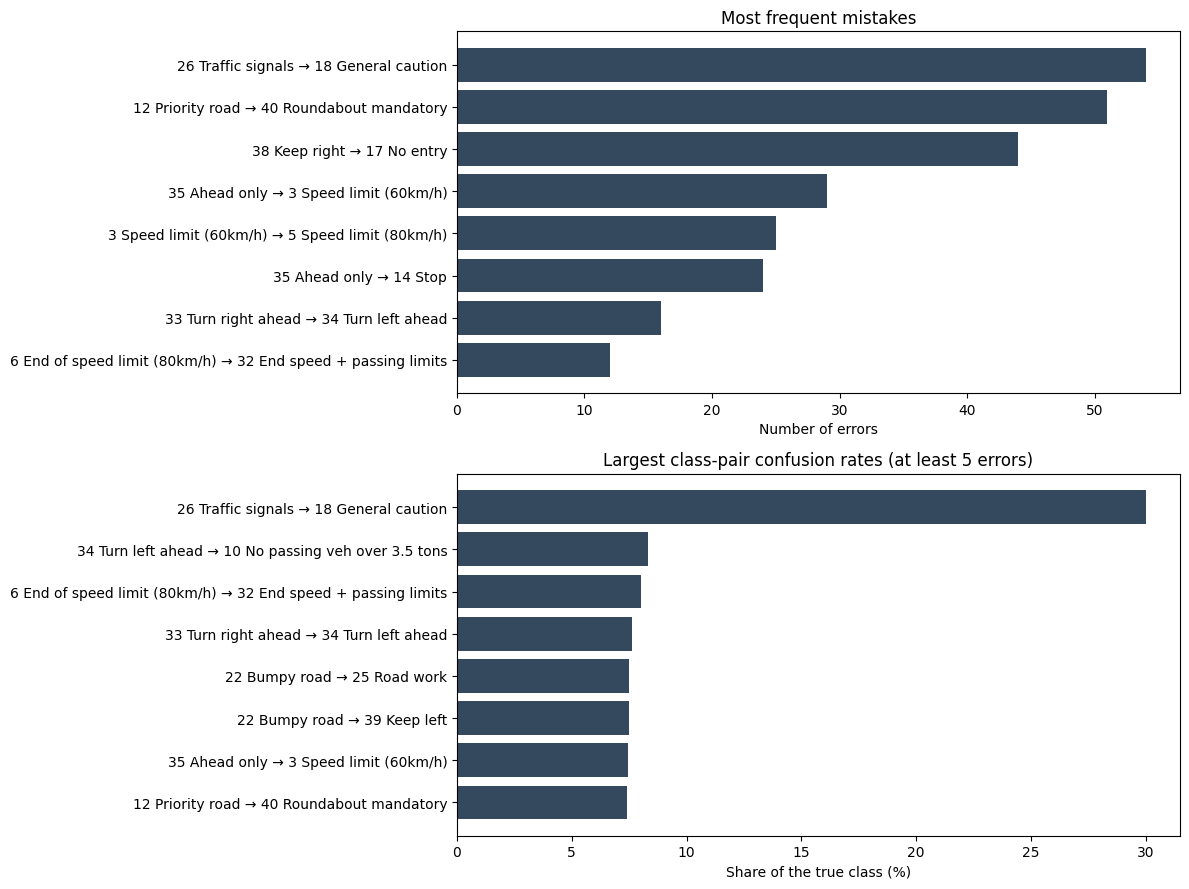

In [4]:
wrong = baseline[~baseline["correct"]]
pairs = (wrong.groupby(["true_label", "prediction"])
         .size().reset_index(name="errors")
         .sort_values("errors", ascending=False))
class_counts = baseline.groupby("true_label").size()
pairs["class_total"] = pairs["true_label"].map(class_counts)
pairs["rate_pct"] = 100 * pairs["errors"] / pairs["class_total"]
pairs["pair"] = [
    f"{a} {model_name(a)} → {b} {model_name(b)}"
    for a, b in zip(pairs.true_label, pairs.prediction)
]

display(pairs[["pair", "errors", "class_total", "rate_pct"]].head(10).round(2))

fig, axes = plt.subplots(2, 1, figsize=(12, 9))
most_errors = pairs.head(8).sort_values("errors")
axes[0].barh(most_errors.pair, most_errors.errors, color=COLORS["overall"])
axes[0].set(title="Most frequent mistakes", xlabel="Number of errors")

highest_rates = pairs[pairs.errors >= 5].nlargest(8, "rate_pct").sort_values("rate_pct")
axes[1].barh(highest_rates.pair, highest_rates.rate_pct, color=COLORS["overall"])
axes[1].set(title="Largest class-pair confusion rates (at least 5 errors)",
            xlabel="Share of the true class (%)")
plt.tight_layout()
fig.savefig(OUT / "01_full_test_confusions.png", dpi=160, bbox_inches="tight")
plt.show()

The unblurred model correctly predicts **12,046 of 12,630 images (95.38%)**. Its most frequent individual error is **Class 26 (Traffic signals) → Class 18 (General caution)**: 54 out of 180 Class 26 images (30%) receive that specific wrong label. This pattern appears in the full test set, not a small sample.

## 3. Research question and hypothesis

**Question:** Why might mild Gaussian blur improve recognition of traffic-signal signs even if it harms overall accuracy?

**Hypothesis:** Mild smoothing might reduce distracting fine details in some small images, while stronger smoothing may remove the sign details needed for recognition. We test this by comparing the same images at different blur levels, then looking at image properties and individual prediction changes. These are possible explanations, not established causes.

## 4. Experiment — blur every image

We apply Gaussian blur to the original image *before* the model's usual preprocessing. We keep the same 12,630 images and use radii 0, 0.5, 1, 1.5, 2, 2.5, 3, and 5. The cache uses the original experiment settings; changing the model or dataset requires a separate results folder.

In [5]:
tables = [baseline]
for radius in BLUR_LEVELS[1:]:
    tables.append(run_one_blur(radius))

results = pd.concat(tables, ignore_index=True)
results["correct"] = results["true_label"] == results["prediction"]

assert len(results) == len(test) * len(BLUR_LEVELS)
assert not results.duplicated(["blur", "image_id"]).any()
assert results.groupby("blur").image_id.nunique().eq(len(test)).all()
assert (results["true_label"] == results["image_id"].map(dict(enumerate(labels)))).all()

results.to_csv(OUT / "all_predictions.csv", index=False)
print(f"Saved {len(results):,} predictions across {len(BLUR_LEVELS)} blur levels")

Blur 0.5: 99 chunks ready
Blur 1: 99 chunks ready
Blur 1.5: 99 chunks ready
Blur 2: 99 chunks ready
Blur 2.5: 99 chunks ready
Blur 3: 99 chunks ready
Blur 5: 99 chunks ready
Saved 101,040 predictions across 8 blur levels


## 5. Visualizations — overall accuracy versus Class 26

The first comparison tests whether the blur effect is general or class-specific.

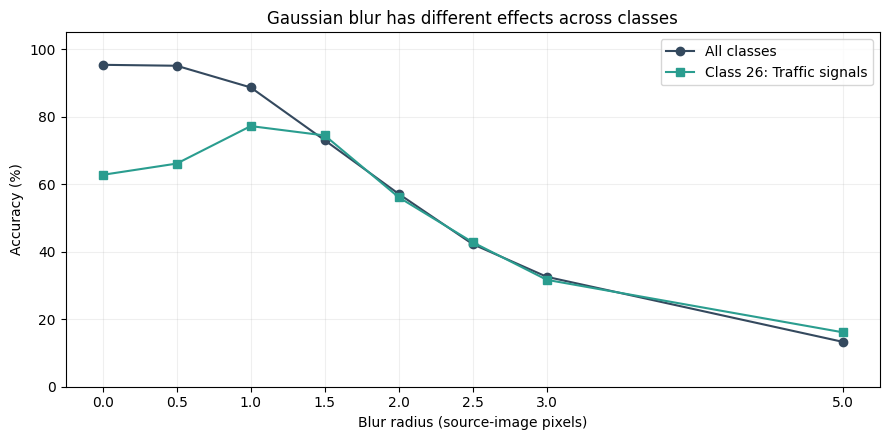

,overall_accuracy_pct,class_26_accuracy_pct
blur,,
0.0,95.38,62.78
0.5,95.10,66.11
1.0,88.67,77.22
1.5,73.02,74.44
2.0,57.12,56.11
2.5,42.22,42.78
3.0,32.56,31.67
5.0,13.29,16.11


In [6]:
overall = results.groupby("blur")["correct"].mean().reindex(BLUR_LEVELS)
per_class = (results.groupby(["true_label", "blur"])["correct"]
             .agg(["size", "mean"]).reset_index())
per_class.columns = ["true_label", "blur", "images", "accuracy"]
per_class.to_csv(OUT / "class_accuracy_by_blur.csv", index=False)

class_26_accuracy = (per_class[per_class.true_label == FOCUS_CLASS]
                     .set_index("blur")["accuracy"].reindex(BLUR_LEVELS))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(BLUR_LEVELS, overall * 100, "o-", color=COLORS["overall"], label="All classes")
ax.plot(BLUR_LEVELS, class_26_accuracy * 100, "s-", color=COLORS["correct"],
        label=f"Class {FOCUS_CLASS}: {model_name(FOCUS_CLASS)}")
ax.set(title="Gaussian blur has different effects across classes",
       xlabel="Blur radius (source-image pixels)", ylabel="Accuracy (%)",
       xticks=BLUR_LEVELS, ylim=(0, 105))
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
fig.savefig(OUT / "02_overall_vs_classes.png", dpi=160)
plt.show()

display(pd.DataFrame({"overall_accuracy_pct": overall * 100,
                      "class_26_accuracy_pct": class_26_accuracy * 100}).round(2))

At blur radius **1.0**, overall accuracy decreases from **95.38% to 88.67%** (−6.71 percentage points). However, Class 26 (Traffic signals) accuracy increases from **62.78% to 77.22%** (+14.44 percentage points).

This shows that Gaussian blur affects different traffic-sign classes differently. Mild blur helps the model recognize more Class 26 images, but reduces overall performance. At stronger blur levels, accuracy decreases substantially for both.

## 5A. Is the improvement unique to Class 26?

The previous figure compares Class 26 with overall accuracy. To see whether this is an unusual pattern, we also compare **all 43 classes** across the same eight blur levels. Each row of the heatmap is one traffic-sign class and each column is a blur radius. Brighter colors mean higher accuracy.

This is **not another experiment**: the chart uses the predictions already collected for all 12,630 test images. We also show the classes with the largest improvements and deteriorations at radius 1.

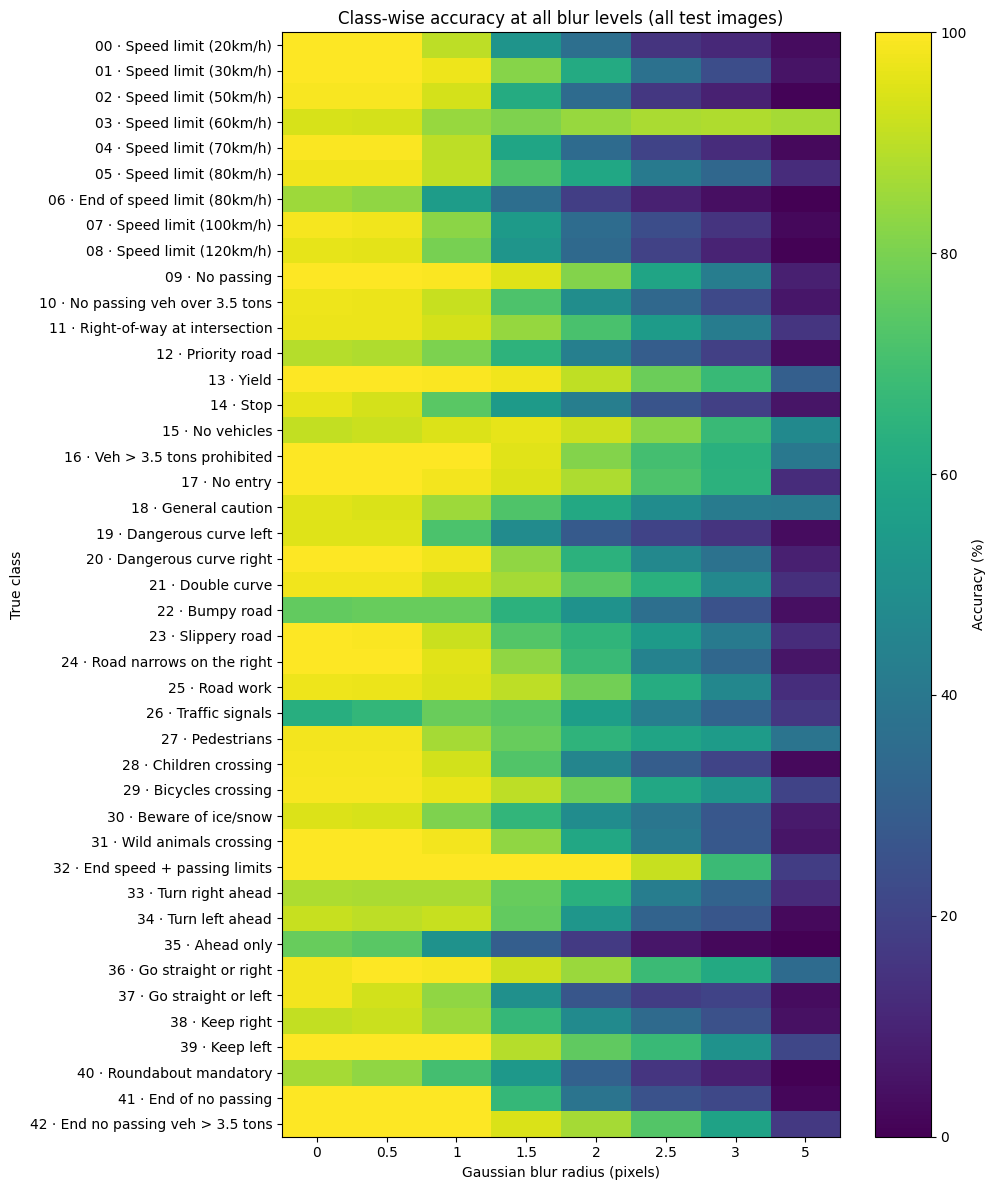

Largest improvements at radius 1.0:


,class,images,no_blur,blur_1,change_percentage_points
26,26,180,0.628,0.772,14.444
15,15,210,0.910,0.948,3.810
22,22,120,0.758,0.767,0.833
36,36,120,0.983,0.992,0.833
16,16,150,1.000,1.000,0.000
32,32,60,1.000,1.000,0.000
34,34,120,0.917,0.917,0.000
39,39,90,1.000,1.000,0.000
41,41,60,1.000,1.000,0.000
42,42,90,1.000,1.000,0.000


Largest deteriorations at radius 1.0:


,class,images,no_blur,blur_1,change_percentage_points
6,6,150,0.853,0.553,-30.000
35,35,390,0.767,0.510,-25.641
19,19,60,0.950,0.717,-23.333
14,14,270,0.963,0.744,-21.852
8,8,450,0.962,0.793,-16.889
40,40,90,0.867,0.700,-16.667
7,7,450,0.984,0.824,-16.000
37,37,60,0.983,0.833,-15.000
30,30,150,0.947,0.807,-14.000
27,27,60,0.983,0.867,-11.667


In [7]:
per_class = results.groupby(["true_label", "blur"], as_index=False).agg(
    images=("image_id", "size"), accuracy=("correct", "mean"))
heat = (per_class.pivot(index="true_label", columns="blur", values="accuracy")
        .reindex(index=np.arange(43), columns=BLUR_LEVELS))
fig, ax = plt.subplots(figsize=(10, 12))
mat = ax.imshow(heat.to_numpy() * 100, aspect="auto", vmin=0, vmax=100, cmap="viridis")
ax.set(xticks=range(len(BLUR_LEVELS)), xticklabels=BLUR_LEVELS,
       yticks=range(43), yticklabels=[f"{i:02d} · {model_name(i)}" for i in range(43)],
       xlabel="Gaussian blur radius (pixels)", ylabel="True class",
       title="Class-wise accuracy at all blur levels (all test images)")
fig.colorbar(mat, ax=ax, label="Accuracy (%)")
plt.tight_layout()
fig.savefig(OUT / "03_class_response_heatmap.png", dpi=160)
plt.show()

change_by_class = pd.DataFrame({
    "class": np.arange(43),
    "images": [int((labels == c).sum()) for c in range(43)],
    "no_blur": heat[0].to_numpy(),
    "blur_1": heat[1].to_numpy(),
})
change_by_class["change_percentage_points"] = 100 * (change_by_class.blur_1 - change_by_class.no_blur)
print("Largest improvements at radius 1.0:")
display(change_by_class.nlargest(10, "change_percentage_points").round(3))
print("Largest deteriorations at radius 1.0:")
display(change_by_class.nsmallest(10, "change_percentage_points").round(3))

**Observation:** Class 26 (Traffic signals) has the largest improvement at radius 1 (**+14.44 percentage points**). The next largest gain is Class 15 (**+3.81 points**), while many classes become less accurate; for example, Class 6 decreases by **30 points**.

This makes the Class 26 result worth investigating: blur is **not generally beneficial** for the classifier. The heatmap shows an input-output pattern, but it does not prove which visual features cause the difference.

## 6. Where do Class 26 predictions go?

Class 26 can be correctly predicted, confused with Class 18, or predicted as another class. We compare all **180 Class 26 images**, without sampling.

,correct_26,confused_18,other,total,accuracy_pct,confusion_18_pct
blur,,,,,,
0.0,113,54,13,180,62.78,30.00
0.5,119,50,11,180,66.11,27.78
1.0,139,32,9,180,77.22,17.78
1.5,134,22,24,180,74.44,12.22
2.0,101,30,49,180,56.11,16.67
2.5,77,35,68,180,42.78,19.44
3.0,57,56,67,180,31.67,31.11
5.0,29,68,83,180,16.11,37.78


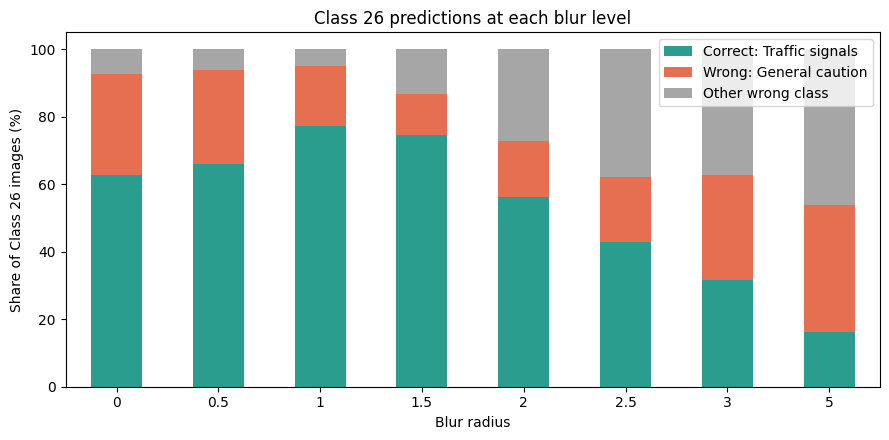

In [8]:
focus = results[results.true_label == FOCUS_CLASS].copy()
focus_ids = np.flatnonzero(labels == FOCUS_CLASS)

counts = pd.DataFrame(index=BLUR_LEVELS)
for radius in BLUR_LEVELS:
    current = focus[focus.blur == radius].prediction
    counts.loc[radius, "correct_26"] = (current == FOCUS_CLASS).sum()
    counts.loc[radius, "confused_18"] = (current == CONFUSED_CLASS).sum()
    counts.loc[radius, "other"] = (~current.isin([FOCUS_CLASS, CONFUSED_CLASS])).sum()
counts = counts.astype(int)
counts.index.name = "blur"
counts["total"] = counts.sum(axis=1)
counts["accuracy_pct"] = 100 * counts.correct_26 / counts.total
counts["confusion_18_pct"] = 100 * counts.confused_18 / counts.total
assert counts.total.eq(len(focus_ids)).all()
counts.to_csv(OUT / "class26_blur_outcomes.csv")
display(counts.round(2))

parts = 100 * counts[["correct_26", "confused_18", "other"]] / len(focus_ids)
fig, ax = plt.subplots(figsize=(9, 4.5))
parts.plot(kind="bar", stacked=True, ax=ax,
           color=[COLORS["correct"], COLORS["confused"], COLORS["other"]])
ax.set(title="Class 26 predictions at each blur level", xlabel="Blur radius",
       ylabel="Share of Class 26 images (%)")
ax.set_xticklabels([str(x) for x in BLUR_LEVELS], rotation=0)
ax.legend(["Correct: Traffic signals", "Wrong: General caution", "Other wrong class"])
plt.tight_layout()
fig.savefig(OUT / "04_class26_blur_effect.png", dpi=160)
plt.show()

Without blur, **113** Class 26 images are correct, **54** are labelled Class 18, and **13** receive another label. At radius 1 the counts are **139**, **32**, and **9**, respectively. At radius 1.5, the specific Class 18 confusion falls further (to **22**) but total Class 26 accuracy also falls. Fixing one error type is not the same as maximizing accuracy.

## 7. Which individual predictions change?

We compare the predictions for the *same images* at radius 0 and 1. This separates corrected errors from new mistakes.

,images
group,
Still correct,104
Fixed: wrong → correct,35
Still incorrect,32
Harmed: correct → wrong,9


Blur 1,Correct (26),Class 18,Other
No blur,,,
Correct (26),104,8,1
Class 18,30,24,0
Other,5,0,8


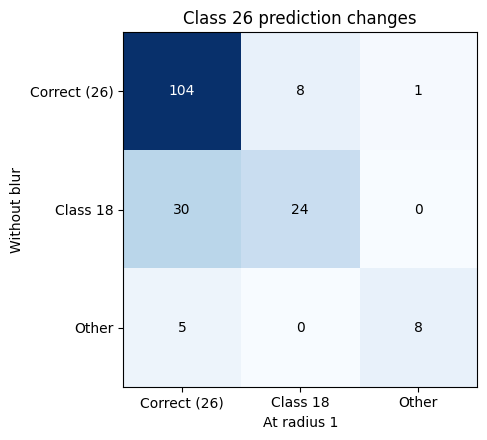

In [9]:
preds = focus.pivot(index="image_id", columns="blur", values="prediction").sort_index()
prob_26 = focus.pivot(index="image_id", columns="blur", values="p_26").sort_index()
prob_18 = focus.pivot(index="image_id", columns="blur", values="p_18").sort_index()

transitions = pd.DataFrame({
    "image_id": preds.index,
    "baseline_prediction": preds[0].to_numpy(),
    "mild_prediction": preds[1].to_numpy(),
    "strong_prediction": preds[5].to_numpy(),
    "p26_before": prob_26[0].to_numpy(),
    "p26_after": prob_26[1].to_numpy(),
    "p18_before": prob_18[0].to_numpy(),
    "p18_after": prob_18[1].to_numpy(),
})
transitions["delta_p26"] = transitions.p26_after - transitions.p26_before
transitions["delta_p18"] = transitions.p18_after - transitions.p18_before

# Four outcome groups describe what happened to each image.
transitions["group"] = "Still incorrect"
transitions.loc[(transitions.baseline_prediction == FOCUS_CLASS) &
                (transitions.mild_prediction == FOCUS_CLASS), "group"] = "Still correct"
transitions.loc[(transitions.baseline_prediction != FOCUS_CLASS) &
                (transitions.mild_prediction == FOCUS_CLASS), "group"] = "Fixed: wrong → correct"
transitions.loc[(transitions.baseline_prediction == FOCUS_CLASS) &
                (transitions.mild_prediction != FOCUS_CLASS), "group"] = "Harmed: correct → wrong"
transitions.to_csv(OUT / "class26_individual_transitions.csv", index=False)
display(transitions.group.value_counts().to_frame("images"))

# Compare correct / Class 18 / other prediction labels before and after blur.
def group_label(prediction):
    if prediction == FOCUS_CLASS:
        return "Correct (26)"
    if prediction == CONFUSED_CLASS:
        return "Class 18"
    return "Other"

before = [group_label(x) for x in transitions.baseline_prediction]
after = [group_label(x) for x in transitions.mild_prediction]
order = ["Correct (26)", "Class 18", "Other"]
transition_table = pd.crosstab(pd.Categorical(before, categories=order),
                               pd.Categorical(after, categories=order), dropna=False)
transition_table.index.name = "No blur"
transition_table.columns.name = "Blur 1"
display(transition_table)

matrix = transition_table.to_numpy()
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.imshow(matrix, cmap="Blues")
ax.set(xticks=range(3), yticks=range(3), xticklabels=order, yticklabels=order,
       title="Class 26 prediction changes", xlabel="At radius 1", ylabel="Without blur")
for row in range(3):
    for col in range(3):
        value = matrix[row, col]
        ax.text(col, row, str(value), ha="center", va="center",
                color="white" if value > matrix.max() / 2 else "black")
plt.tight_layout()
fig.savefig(OUT / "05_class26_transition_matrix.png", dpi=160)
plt.show()

Mild blur **fixes 35 errors** but also **introduces 9 new errors** among Class 26 images (a net gain of 26 correct predictions). In particular, **30 images change from Class 18 to the correct Class 26**. Another **8** switch in the opposite direction. We therefore need to look beyond net accuracy.

## 8. Are changes related to image properties?

For each unblurred image, we record its smaller side length, average grayscale brightness, contrast and a simple measure of visual detail. We then compare Class 26 accuracy before and after blur within three groups for each property. The groups are descriptive, not causal tests.

In [10]:
FEATURES_CSV = OUT / "image_properties.csv"
if FEATURES_CSV.exists():
    image_properties = pd.read_csv(FEATURES_CSV)
else:
    rows = []
    for start in range(0, len(test), 256):
        end = min(start + 256, len(test))
        items = test[start:end]["image"]
        for image_id, im in zip(range(start, end), items):
            im = im.convert("RGB")
            w, h = im.size
            gray = np.asarray(im.convert("L").resize((64, 64), Image.Resampling.BILINEAR), dtype=np.float32) / 255.0
            edge_x = np.abs(np.diff(gray, axis=1)).mean()
            edge_y = np.abs(np.diff(gray, axis=0)).mean()
            rows.append({"image_id": image_id, "true_label": int(labels[image_id]),
                         "width": w, "height": h, "min_size": min(w, h),
                         "brightness": float(gray.mean()),
                         "contrast": float(gray.std()),
                         "detail_score": float((edge_x + edge_y) / 2)})
        if (end % 2048) < 256 or end == len(test):
            print(f"Measured {end:,} / {len(test):,} image properties")
    image_properties = pd.DataFrame(rows)
    image_properties.to_csv(FEATURES_CSV, index=False)

assert len(image_properties) == len(test)
assert image_properties.image_id.is_unique
assert np.array_equal(image_properties.sort_values("image_id").true_label.to_numpy(), labels)
print("Full-dataset image-property summary:")
display(image_properties[["min_size", "brightness", "contrast", "detail_score"]].describe().round(3))

Measured 2,048 / 12,630 image properties
Measured 4,096 / 12,630 image properties
Measured 6,144 / 12,630 image properties
Measured 8,192 / 12,630 image properties
Measured 10,240 / 12,630 image properties
Measured 12,288 / 12,630 image properties
Measured 12,630 / 12,630 image properties
Full-dataset image-property summary:


,min_size,brightness,contrast,detail_score
count,12630.000,12630.000,12630.000,12630.000
mean,49.034,0.319,0.161,0.024
std,23.397,0.183,0.093,0.015
min,25.000,0.035,0.014,0.002
25%,33.000,0.176,0.081,0.012
50%,42.000,0.287,0.153,0.022
75%,56.000,0.436,0.233,0.034
max,232.000,0.937,0.436,0.093


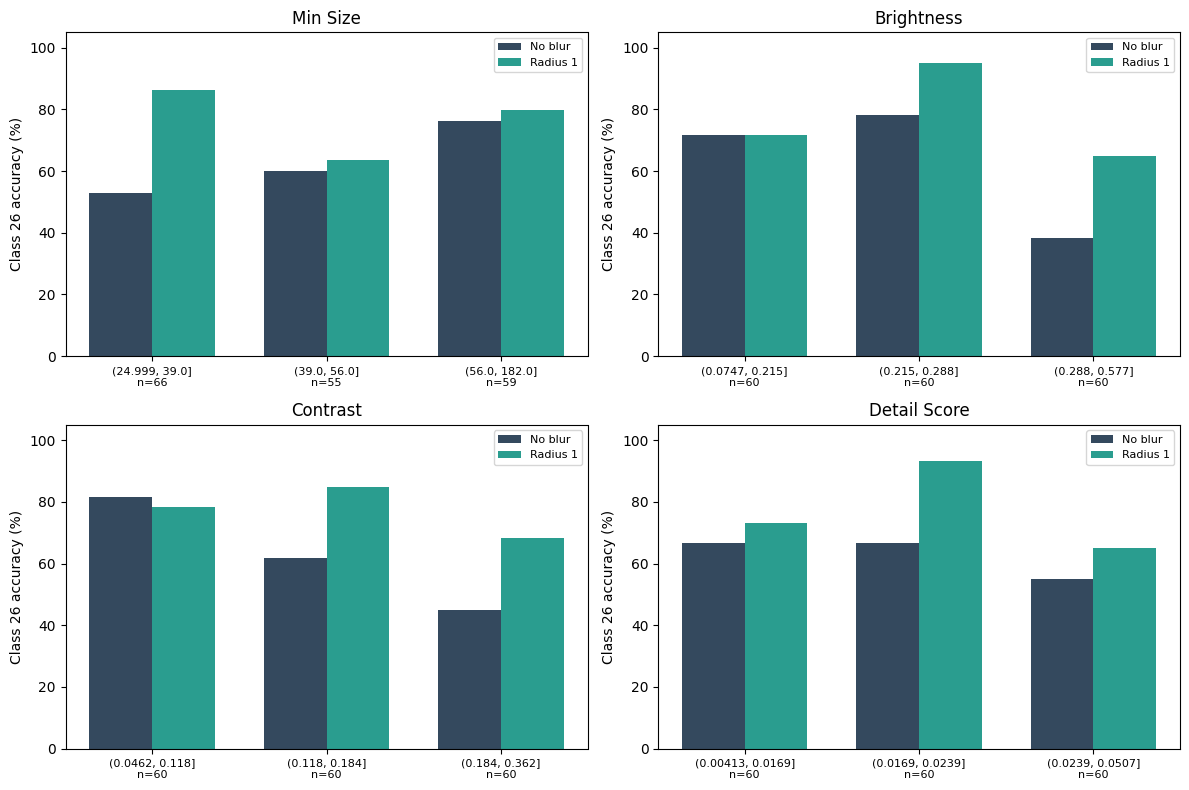

,property,range,images,acc_before,acc_after,delta_pp
0,min_size,"(24.999, 39.0]",66,0.530,0.864,33.333
1,min_size,"(39.0, 56.0]",55,0.600,0.636,3.636
2,min_size,"(56.0, 182.0]",59,0.763,0.797,3.390
3,brightness,"(0.0747, 0.215]",60,0.717,0.717,0.000
4,brightness,"(0.215, 0.288]",60,0.783,0.950,16.667
5,brightness,"(0.288, 0.577]",60,0.383,0.650,26.667
6,contrast,"(0.0462, 0.118]",60,0.817,0.783,-3.333
7,contrast,"(0.118, 0.184]",60,0.617,0.850,23.333
8,contrast,"(0.184, 0.362]",60,0.450,0.683,23.333
9,detail_score,"(0.00413, 0.0169]",60,0.667,0.733,6.667


In [11]:
class_properties = image_properties[image_properties.true_label == FOCUS_CLASS].merge(
    transitions, on="image_id", validate="one_to_one")
class_properties["correct_before"] = class_properties.baseline_prediction == FOCUS_CLASS
class_properties["correct_after"] = class_properties.mild_prediction == FOCUS_CLASS
class_properties.to_csv(OUT / "class26_properties_and_changes.csv", index=False)

properties = ["min_size", "brightness", "contrast", "detail_score"]
subgroup_rows = []
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.flat, properties):
    # Quantile bins use the same image-property grouping as the original experiment.
    bins = pd.qcut(class_properties[feature], q=3, duplicates="drop")
    group_data = class_properties.assign(group=bins)
    summary = group_data.groupby("group", observed=True).agg(
        images=("image_id", "size"),
        before=("correct_before", "mean"),
        after=("correct_after", "mean"))

    x = np.arange(len(summary))
    ax.bar(x - 0.18, summary.before * 100, width=0.36,
           color=COLORS["overall"], label="No blur")
    ax.bar(x + 0.18, summary.after * 100, width=0.36,
           color=COLORS["correct"], label="Radius 1")
    ax.set(title=feature.replace("_", " ").title(), ylabel="Class 26 accuracy (%)",
           xticks=x, xticklabels=[f"{interval}\nn={num}" for interval, num in zip(summary.index, summary.images)],
           ylim=(0, 105))
    ax.tick_params(axis="x", labelsize=8)
    ax.legend(fontsize=8)

    for interval, row in summary.iterrows():
        subgroup_rows.append({"property": feature, "range": str(interval),
                              "images": int(row.images), "acc_before": row.before,
                              "acc_after": row.after,
                              "delta_pp": 100 * (row.after - row.before)})
plt.tight_layout()
fig.savefig(OUT / "07_image_property_subgroups.png", dpi=160)
plt.show()

subgroups = pd.DataFrame(subgroup_rows)
subgroups.to_csv(OUT / "class26_subgroups.csv", index=False)
display(subgroups.round(3))

The **smallest images** (shortest side ≤39 pixels, 66 images) improve from **53.0% to 86.4%** accuracy with blur radius 1. In comparison, the two larger image groups improve by only about **3–4 percentage points**.

Brighter images and images with medium or high contrast also show larger improvements than their lowest groups. Images with a medium detail score show the largest improvement within the detail comparison.

These results suggest that image size and visual characteristics may influence how the model responds to blur. However, these properties may be related, so we cannot identify a single cause from these comparisons alone.

## 9. Examples and counterexamples

These are actual test images from four outcome groups. Each row shows the same image before blur, at radius 1, and at radius 5. We select one middle-sized example per group for a compact overview.

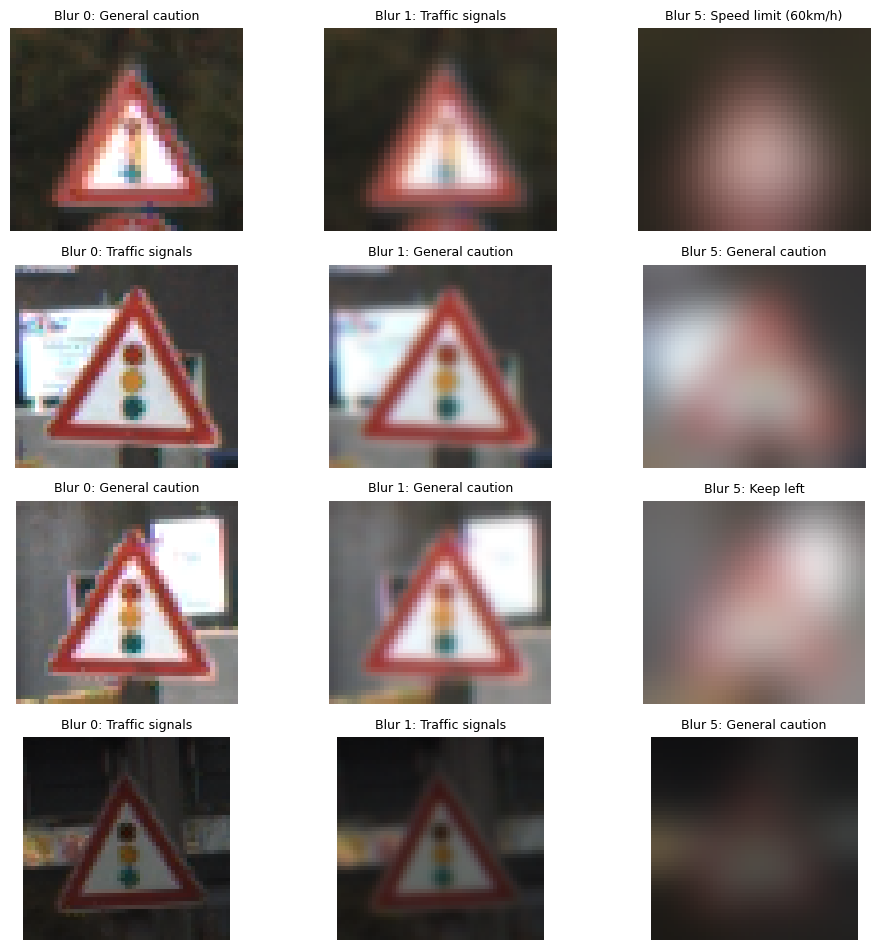

In [12]:
example_groups = {
    "Fixed": transitions[transitions.group == "Fixed: wrong → correct"].image_id.tolist(),
    "Harmed": transitions[transitions.group == "Harmed: correct → wrong"].image_id.tolist(),
    "Still wrong as 18": transitions[
        (transitions.baseline_prediction == CONFUSED_CLASS) &
        (transitions.mild_prediction == CONFUSED_CLASS)].image_id.tolist(),
    "Still correct": transitions[
        (transitions.baseline_prediction == FOCUS_CLASS) &
        (transitions.mild_prediction == FOCUS_CLASS)].image_id.tolist(),
}

size_by_id = image_properties.set_index("image_id")["min_size"]
examples = []
for name, ids in example_groups.items():
    if ids:
        ids = sorted(ids, key=lambda i: (size_by_id.loc[i], i))
        examples.append((name, ids[len(ids) // 2]))

fig, axes = plt.subplots(len(examples), 3, figsize=(10, 2.4 * len(examples)), squeeze=False)
for row, (name, image_id) in enumerate(examples):
    picture = test[int(image_id)]["image"].convert("RGB")
    for col, radius in enumerate([0, 1, 5]):
        shown = picture if radius == 0 else picture.filter(ImageFilter.GaussianBlur(radius))
        prediction = int(preds.loc[image_id, radius])
        axes[row, col].imshow(shown)
        axes[row, col].set_title(f"Blur {radius:g}: {model_name(prediction)}", fontsize=9)
        axes[row, col].axis("off")
    axes[row, 0].set_ylabel(f"{name}\nID {image_id}", fontsize=9)
plt.tight_layout()
fig.savefig(OUT / "09_examples_main.png", dpi=160, bbox_inches="tight")
plt.show()

The examples show that blur affects individual images differently. In the first example, mild blur corrects a prediction from General caution to Traffic signals. In the second, blur introduces the opposite error. The third example remains incorrect, while the fourth remains correct under mild blur.

At radius 5, all four images are misclassified as important visual details become less visible. These examples suggest that smoothing can sometimes help recognition, but the effect depends on the image. They do not establish a single cause for the model's behavior.

## 10. Conclusion

The model performs well overall on the original GTSRB test split (**95.38% accuracy**), but it makes a repeated Class 26 → Class 18 error (**54 of 180 Class 26 images**). Radius-1 Gaussian blur improves Class 26 accuracy by **14.44 percentage points**, even though overall accuracy drops by **6.71 percentage points**. It fixes 35 Class 26 errors and introduces 9 new ones. The 43-class heatmap confirms that Class 26 has the largest accuracy improvement at radius 1, while many other classes become less accurate.

The gain is concentrated in smaller source images. This supports the possibility that smoothing before resizing changes useful visual details at low resolution; it does **not** tell us exactly which features the model uses. At stronger blur levels, fine visual details become less visible, and recognition accuracy decreases.

**Limitations:** The analysis is black-box and exploratory. We chose the focus class and interesting blur level using this test set. Several images may show the same physical sign, so they are not necessarily independent. Image-property associations are not causal evidence, and conclusions may not generalize to a different model or dataset.